# Day 08. Exercise 04
# Regression

## 0. Imports

In [56]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Preprocessing

1. Read the file [`checker_regression.csv`](https://drive.google.com/file/d/1L8auBzJEghWFewznhhFpcrqxW4GqcfRY/view?usp=sharing).
2. Fill the missing values in it with `0`.
3. Make a split of your dataset on train and test with parameters `test_size=0.2`.

In [57]:
df = pd.read_csv("../data/checker_regression.csv")
df.head(5)

,uid,num_commits,pageviews,AVG(diff)
0,user_1,62,28.0,NaN
1,user_1,62,28.0,NaN
2,user_1,62,28.0,NaN
3,user_1,62,28.0,NaN
4,user_1,62,28.0,NaN


In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   uid          77 non-null     object 
 1   num_commits  77 non-null     int64  
 2   pageviews    59 non-null     float64
 3   AVG(diff)    18 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 2.5+ KB


In [59]:
df['AVG(diff)'] = df['AVG(diff)'].fillna(0)
df['pageviews'] = df['pageviews'].fillna(0)

In [60]:
df = df.drop(columns=['uid'])

In [61]:
X = df.drop(columns=['AVG(diff)'])
y = df['AVG(diff)']

In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   num_commits  77 non-null     int64  
 1   pageviews    77 non-null     float64
 2   AVG(diff)    77 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 1.9 KB


In [63]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=21)

## 2. Crossvalidation

1. Write a function `crossval` that takes as arguments: `n_splits` for `KFold()`, `X`, `y`, model instantiated class with the parameters of the model (keep in mind: `random_state=21`) and returns for a given model class a result like this:

```
train -  2696.4496895424836   |   test -  1589.9979527104958
train -  2660.957874001452   |   test -  2075.102636027137
train -  2847.315529246795   |   test -  320.911928168403
train -  2500.7691099659237   |   test -  4132.461382030178
train -  2643.927917295123   |   test -  2237.8140952197878
train -  2396.295678819444   |   test -  4509.650064742476
train -  2003.402267924976   |   test -  8403.491474908551
train -  2531.876094212613   |   test -  3135.944102735099
train -  2683.1795186023123   |   test -  1796.01426292594
train -  2537.1192483996338   |   test -  3439.29824116941
Average RMSE on crossval is 3164.0686140637476
```

2. Run the function for `LinearRegression`, `DecisionTreeRegressor`, `RandomForestRegressor`. You may choose the parameters by yourself, but find the good enough for you.

In [64]:
def crossval(n_splits, X, y, model):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=21)
    rmses_test = []
    for train_index, test_index in kf.split(X):
        X_tr, X_te = X.iloc[train_index], X.iloc[test_index]
        y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
        model.fit(X_tr, y_tr)
        pred_tr = model.predict(X_tr)
        pred_te = model.predict(X_te)
        rmse_tr = np.sqrt(mean_squared_error(y_tr, pred_tr))
        rmse_te = np.sqrt(mean_squared_error(y_te, pred_te))
        print("train - ", rmse_tr, "  |   test - ", rmse_te)
        rmses_test.append(rmse_te)
    print("Average RMSE on crossval is", np.mean(rmses_test))
    return np.mean(rmses_test)


In [65]:
crossval(10, X_train, y_train, LinearRegression())

train -  43.85193506275826   |   test -  42.01528915581881
train -  41.80101617667962   |   test -  58.19069641798876
train -  44.69553999765828   |   test -  34.892720193433675
train -  38.84549642903113   |   test -  76.60149754412575
train -  44.860797582621885   |   test -  31.904314868671182
train -  44.855033493587875   |   test -  30.369016640380945
train -  42.07183083893711   |   test -  56.10331212526736
train -  45.6755157436544   |   test -  16.54400016939582
train -  43.60670981884092   |   test -  45.85548116615201
train -  44.2670184108396   |   test -  39.06886806726505
Average RMSE on crossval is 43.15451963484993


np.float64(43.15451963484993)

In [66]:
crossval(10, X_train, y_train, DecisionTreeRegressor(max_depth=4, random_state=21))

train -  19.084116614201573   |   test -  36.99012309183636
train -  18.011556580555315   |   test -  21.968861130586635
train -  15.825086528558497   |   test -  39.90627039284261
train -  10.782280286739823   |   test -  66.48552195500633
train -  18.00664392909533   |   test -  29.18068058393368
train -  18.242289501666896   |   test -  23.43345187262574
train -  21.630697883080217   |   test -  25.938285909557056
train -  12.685793324531472   |   test -  68.2514346825534
train -  12.203075245795441   |   test -  60.09094072659711
train -  15.976024755970021   |   test -  46.33618096764845
Average RMSE on crossval is 41.85817513131873


np.float64(41.85817513131873)

In [67]:
crossval(10, X_train, y_train, RandomForestRegressor(n_estimators=100, max_depth=25, random_state=21))

train -  14.388980213656279   |   test -  22.904899040674536
train -  14.08370442109272   |   test -  40.26362372976199
train -  14.03673111880095   |   test -  38.26198236161764
train -  12.024615385793538   |   test -  58.178615769949424
train -  14.719802173904668   |   test -  23.735827773095973
train -  15.50409832408609   |   test -  9.565665693858715
train -  14.805370579231832   |   test -  27.332911218962828
train -  12.854871232750863   |   test -  57.020533082065825
train -  13.495696250840465   |   test -  39.07289544200975
train -  14.17194137669018   |   test -  33.93114841361351
Average RMSE on crossval is 35.02681025256103


np.float64(35.02681025256103)

## 3. Predictions and evaluation

1. Make predictions for the test dataset using each of the three models with the finalized parameters.
2. Draw a plot for each of the models where the `x-axis` is the actual average difference and the `y-axis` is the prediction made by a model.
3. How would plot look like in the ideal case? Put the answer to the markdown cell in the end of the section.

In [68]:
lin_reg = LinearRegression()

In [69]:
lin_reg.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [70]:
ling_reg_predicted = lin_reg.predict(X_test)

<Axes: xlabel='AVG(diff)'>

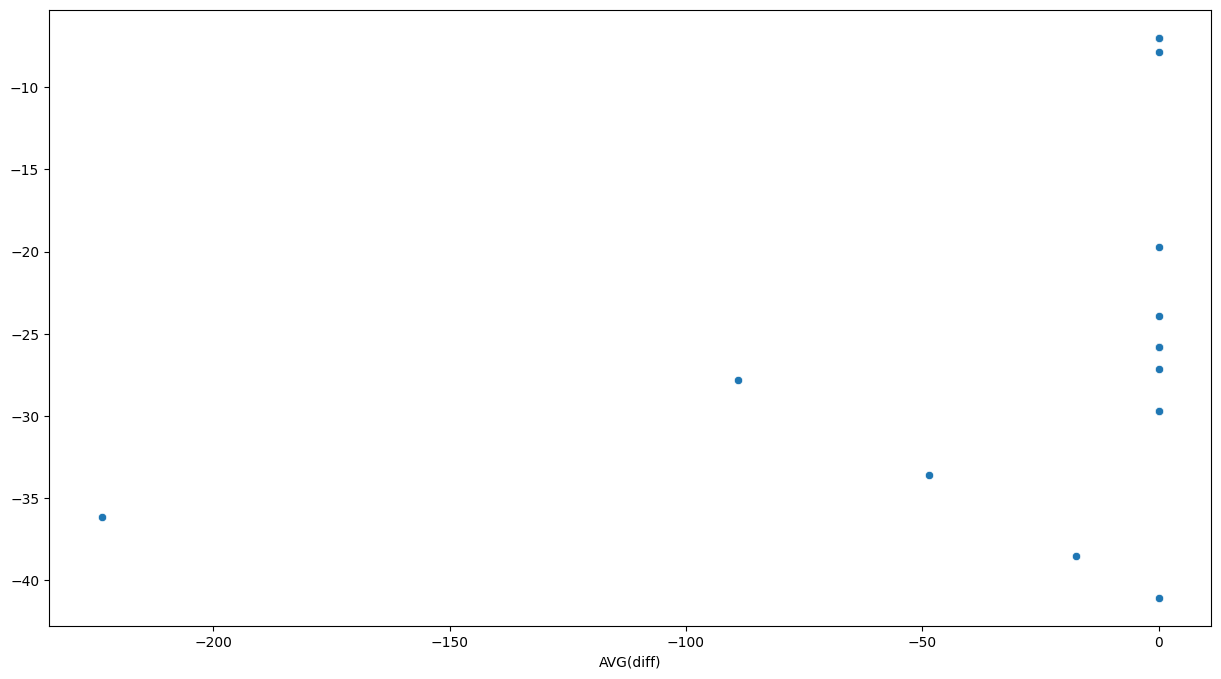

In [71]:
plt.figure(figsize=(15, 8))
sns.scatterplot(x=y_test, y=ling_reg_predicted)

In [72]:
dt_regressor = DecisionTreeRegressor(max_depth=4, random_state=21)

In [73]:
dt_regressor.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,21
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [74]:
dt_regressor_predicted = dt_regressor.predict(X_test)

<Axes: xlabel='AVG(diff)'>

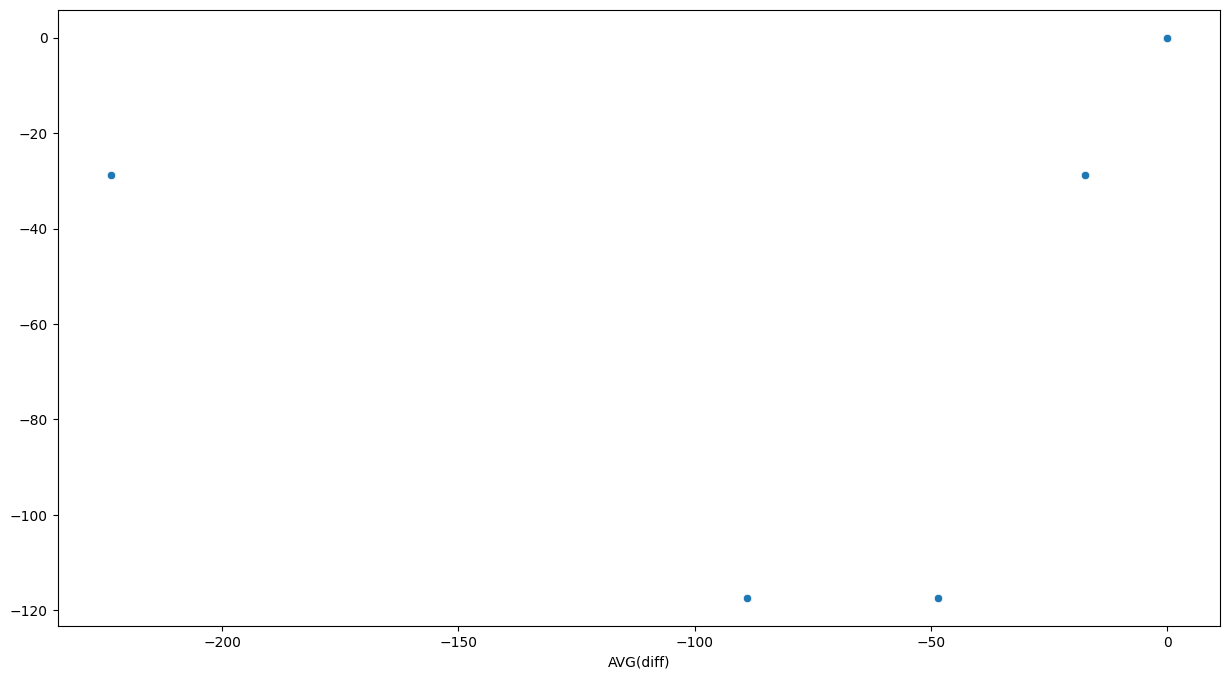

In [75]:
plt.figure(figsize=(15, 8))
sns.scatterplot(x=y_test, y=dt_regressor_predicted)

In [76]:
rf_reg = RandomForestRegressor(n_estimators=100, max_depth=25, random_state=21)

In [77]:
rf_reg.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,25
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [78]:
rf_reg_predicted = rf_reg.predict(X_test)

<Axes: xlabel='AVG(diff)'>

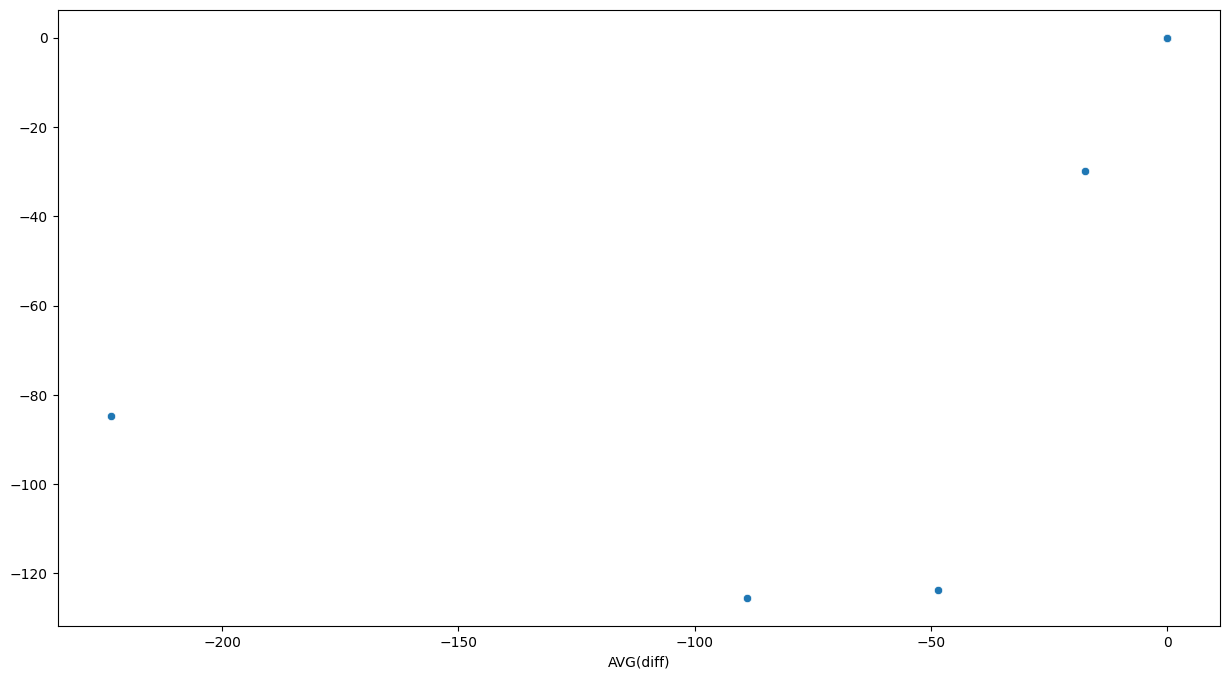

In [79]:
plt.figure(figsize=(15, 8))
sns.scatterplot(x=y_test, y=rf_reg_predicted)

## Diagonal